# Fase 2 — Inferencia temporal

Material de apoyo elaborado con asistencia de IA. El grupo debe revisar y asumir las decisiones metodológicas e interpretar los resultados antes de entregar. No se fabrican observaciones individuales.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'protocolo.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
from common import OUT, PROTOCOL
from data_prep import main as preparar
if not (ROOT / 'data/processed/serie_mensual.csv').exists():
    _ = preparar()
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_colwidth', 100)
display(Markdown('**Protocolo temporal:** desarrollo 2016–2022; calibración 2023; prueba 2024.'))


**Protocolo temporal:** desarrollo 2016–2022; calibración 2023; prueba 2024.

## Hipótesis y decisiones previas

Se usan solo 84 meses de desarrollo. Cuatro contrastes, alfa 0,05 y Bonferroni; se incluyen comparación de medidas apareadas múltiples, comparación de dos medidas apareadas, correlación y regresión robusta. `protocolo.json` se fijó antes de ejecutar modelos. Los supuestos temporales no se sustituyen por una prueba de normalidad.

In [2]:
display(PROTOCOL['hipotesis'])
from phase2 import main as inferir
resultado = inferir()

{'H1': 'No hay alineacion estacional de los rangos mensuales entre anos; Friedman y referencia por desplazamientos circulares dentro de cada ano',
 'H2': 'La distribucion de las diferencias entre promedios del segundo y primer semestre tiene centro cero; Wilcoxon apareado por ano',
 'H3': 'No hay asociacion monotona entre ano y promedio anual; Spearman con desplazamientos circulares de la secuencia anual',
 'H4': 'El coeficiente del rezago de un mes es cero, controlando rezago doce, calendario, tendencia y 2020; OLS con covarianza HAC(12)'}

id  estadistico            p  p_bonferroni       decision
H1    10.493240 4.462000e-01  1.000000e+00 No rechazar H0
H2     8.000000 3.750000e-01  1.000000e+00 No rechazar H0
H3    -0.285714 7.142857e-01  1.000000e+00 No rechazar H0
H4     8.025353 2.908461e-11  1.163385e-10    Rechazar H0


## Verificación de supuestos

Shapiro-Wilk, Q-Q y Levene son diagnósticos. Wilcoxon no exige homogeneidad de varianzas. Los bloques anuales y HAC aproximan la dependencia; no garantizan estabilidad ni exogeneidad.

,prueba,variable,estadistico,p,interpretacion
0,Shapiro-Wilk,Conteos mensuales,0.974224,0.089848,Diagnostico; n pequeno no prueba normalidad. No activa busquedas de pruebas por significancia.
1,Shapiro-Wilk,Diferencias de semestres por ano,0.950462,0.733907,Diagnostico; n pequeno no prueba normalidad. No activa busquedas de pruebas por significancia.
2,Shapiro-Wilk,Residuos OLS,0.971589,0.102542,Diagnostico; n pequeno no prueba normalidad. No activa busquedas de pruebas por significancia.
3,Levene (mediana),Promedios de semestres,0.748488,0.403920,Diagnostico descriptivo; igualdad de varianzas NO es requisito de Wilcoxon apareado.
4,Ljung-Box(1),Residuos OLS,0.070984,0.789910,Diagnostico de dependencia residual; no es una quinta hipotesis primaria.
5,Ljung-Box(6),Residuos OLS,4.673120,0.586368,Diagnostico de dependencia residual; no es una quinta hipotesis primaria.
6,Ljung-Box(12),Residuos OLS,9.088171,0.695382,Diagnostico de dependencia residual; no es una quinta hipotesis primaria.


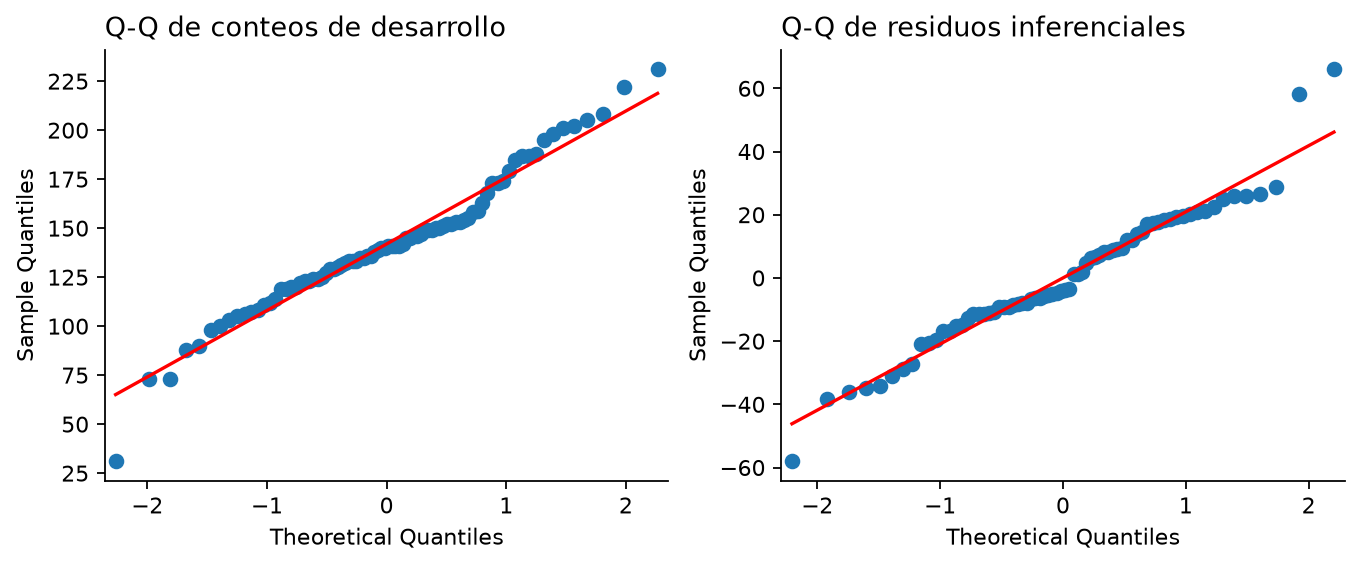

In [3]:
display(pd.read_csv(OUT / 'tables/supuestos_fase2.csv'))
display(Image(filename=str(OUT / 'figures/f2_01_supuestos_qq.png')))

## Resultados de cuatro contrastes

Los IC del 95% son marginales, no simultáneos. Las decisiones de rechazo usan los valores p Bonferroni. Los grados de libertad paramétricos no se inventan para Wilcoxon o referencias circulares.

In [4]:
contrastes = pd.read_csv(OUT / 'tables/contrastes_fase2.csv')
display(contrastes[['id','prueba','estadistico','gl','p','p_bonferroni','efecto','ic_bajo','ic_alto','decision']])

,id,prueba,estadistico,gl,p,p_bonferroni,efecto,ic_bajo,ic_alto,decision
0,H1,Friedman con referencia de desplazamientos circulares por ano,10.493240,11.0,4.462000e-01,1.000000e+00,0.136276,0.093233,0.579131,No rechazar H0
1,H2,"Wilcoxon apareado por ano (bilateral, exacto)",8.000000,NaN,3.750000e-01,1.000000e+00,13.714286,-7.428571,34.144048,No rechazar H0
2,H3,Spearman; referencia circular de la secuencia anual,-0.285714,NaN,7.142857e-01,1.000000e+00,-0.285714,-1.000000,0.686275,No rechazar H0
3,H4,t de coeficiente OLS con HAC(12),8.025353,64.0,2.908461e-11,1.163385e-10,0.575314,0.432102,0.718525,Rechazar H0


H1 y H2 no aportan evidencia concluyente de calendario o diferencia semestral. H3 tiene solo siete referencias circulares: su baja resolución impide alcanzar el umbral corregido. No rechazar no equivale a aceptar ausencia de efecto. H4 sí presenta asociación condicional con el mes anterior bajo los supuestos del modelo; no demuestra capacidad de pronóstico anual.

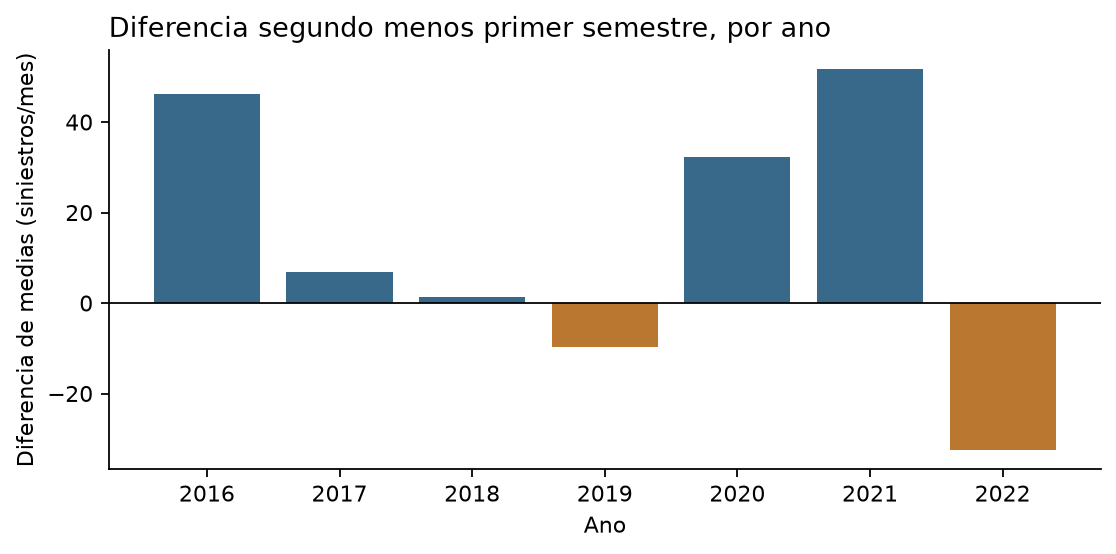

,ano,primero,segundo,diferencia
0,2016,150.666667,196.833333,46.166667
1,2017,157.666667,164.500000,6.833333
2,2018,125.833333,127.166667,1.333333
3,2019,135.666667,126.000000,-9.666667
4,2020,89.666667,121.833333,32.166667
5,2021,136.000000,187.666667,51.666667
6,2022,150.000000,117.500000,-32.500000


In [5]:
display(Image(filename=str(OUT / 'figures/f2_02_semestres.png')))
display(pd.read_csv(OUT / 'tables/diferencias_pareadas_semestres.csv'))

## Bootstrap de pares y bloques

Se remuestrean años con sus semestres emparejados para el efecto medio. El IC clásico t y el bootstrap estiman esa misma diferencia media; el contraste Wilcoxon se refiere a un centro de distribución simétrica y debe distinguirse de ese estimando.

{'estimacion': np.float64(13.714285714285719),
 'bootstrap': array([-7.42857143, 34.14404762]),
 'clasico_t': (np.float64(-14.834089273753186),
  np.float64(42.262660702324624)),
 'nota': 'Ambos IC estiman la diferencia media; Wilcoxon contrasta un centro de diferencias bajo simetria.'}

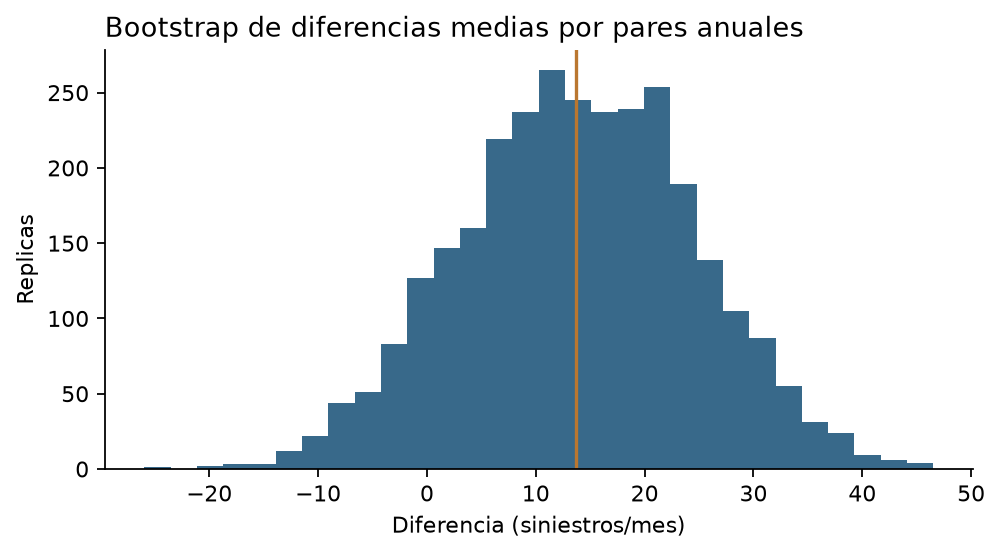

In [6]:
display(resultado['comparacion_ic_media_semestres'])
display(Image(filename=str(OUT / 'figures/f2_03_bootstrap.png')))

,variable,coeficiente,error_estandar_HAC,t,p_sin_ajuste,ic95_inferior,ic95_superior
0,const,-147.264520,69.556786,-2.117184,3.813620e-02,-286.220175,-8.308866
1,rezago_1,0.575314,0.071687,8.025353,2.908461e-11,0.432102,0.718525
2,rezago_12,-0.140127,0.070440,-1.989296,5.094618e-02,-0.280848,0.000594
3,tendencia_ano,-0.289188,1.529535,-0.189069,8.506368e-01,-3.344785,2.766409
4,sin_mes,-1.637818,5.270963,-0.310725,7.570197e-01,-12.167778,8.892141
5,cos_mes,-3.063168,3.296024,-0.929352,3.561986e-01,-9.647734,3.521397
6,dias_mes,7.531073,2.290135,3.288485,1.639214e-03,2.956003,12.106144
7,indicador_2020,-18.523320,5.143445,-3.601345,6.185376e-04,-28.798533,-8.248106


,rezagos_HAC,beta,p,ic_bajo,ic_alto
0,6,0.575314,1.694748e-10,0.423913,0.726714
1,12,0.575314,2.908461e-11,0.432102,0.718525


{'n': 72,
 'r2': np.float64(0.5558890095270519),
 'r2_ajustado': np.float64(0.5073143699440732),
 'coef_rezago1': np.float64(0.5753135942903633),
 'ic_HAC': array([0.43210233, 0.71852486]),
 'ic_OLS': [0.3941051806390765, 0.7565220079416501],
 'ic_bootstrap_bloques': array([0.40565588, 0.74748646]),
 'coeficientes': [{'variable': 'const',
   'coeficiente': -147.2645204634216,
   'error_estandar_HAC': 69.55678601068047,
   't': -2.1171840866944183,
   'p_sin_ajuste': 0.038136197746396684,
   'ic95_inferior': -286.220174535988,
   'ic95_superior': -8.308866390855172},
  {'variable': 'rezago_1',
   'coeficiente': 0.5753135942903633,
   'error_estandar_HAC': 0.0716870113445521,
   't': 8.025353317147104,
   'p_sin_ajuste': 2.908461451422805e-11,
   'ic95_inferior': 0.43210232589794273,
   'ic95_superior': 0.7185248626827839},
  {'variable': 'rezago_12',
   'coeficiente': -0.14012693058240758,
   'error_estandar_HAC': 0.07044047766809121,
   't': -1.9892955758004973,
   'p_sin_ajuste': 0.05

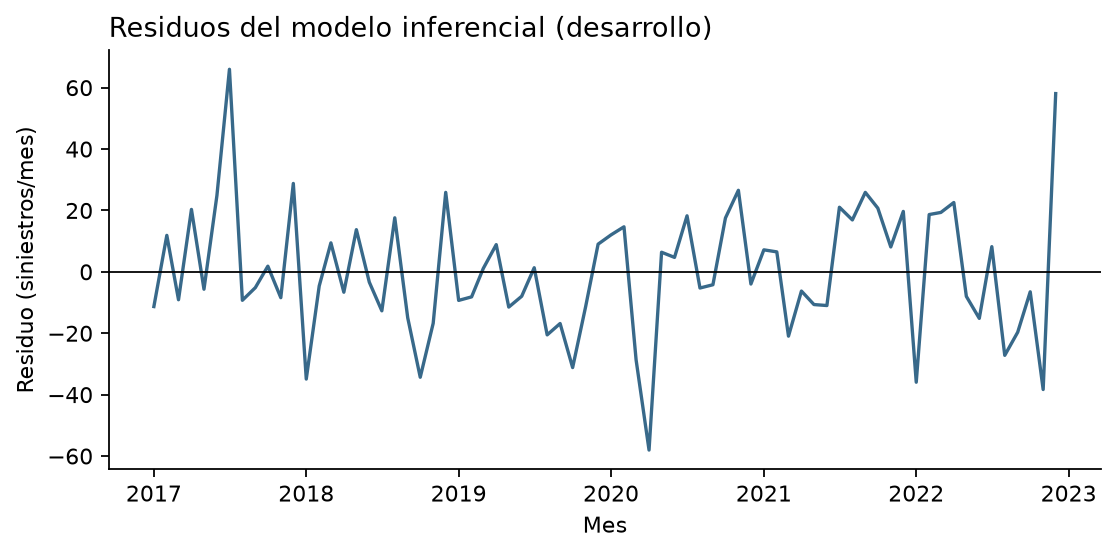

In [7]:
display(pd.read_csv(OUT / 'tables/regresion_inferencial_HAC.csv'))
display(pd.read_csv(OUT / 'tables/sensibilidad_HAC.csv'))
display(resultado['regresion'])
display(Image(filename=str(OUT / 'figures/f2_04_residuos.png')))

## Conclusión y paso a modelado

La asociación con el rezago uno justifica evaluarlo, junto con otras representaciones históricas, sin garantizar su utilidad. El calendario se mantiene como control predefinido y se evalúa por pronóstico. No se usan pruebas para buscar retrospectivamente una combinación significativa. Faltan medidas de exposición y cambios institucionales; ninguna conclusión es causal.